In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import KFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import mean_squared_error
from sklearn.metrics import average_precision_score

import matplotlib.pyplot as plt
import os
from sklearn.utils import shuffle

Load data

In [37]:
# load train and test data
# train_data = pd.read_csv('../data/train.csv')
test_data = pd.read_csv('../data/test.csv')
# id,buildingblock1_smiles,buildingblock2_smiles,buildingblock3_smiles,molecule_smiles,protein_name,binds
# 0,C#CC[C@@H](CC(=O)O)NC(=O)OCC1c2ccccc2-c2ccccc21,C#CCOc1ccc(CN)cc1.Cl,Br.Br.NCC1CCCN1c1cccnn1,C#CCOc1ccc(CNc2nc(NCC3CCCN3c3cccnn3)nc(N[C@@H](CC#C)CC(=O)N[Dy])n2)cc1,BRD4,0

# load DataFrame from a pickle file
train_data_original = pd.read_pickle('../data/train.pkl')
# train_data_short = pd.read_pickle('../data/train_short_9000.pkl')

if not 'train.pkl' in os.listdir('../data'):
    train_data_original.to_pickle('../data/train.pkl')

In [38]:
# print count of unique proteins
print('Train proteins:\n', train_data_original['protein_name'].value_counts())
print('\nTest proteins:\n', test_data['protein_name'].value_counts())

# print count of unique values in binds column
print('\nTrain binds:\n', train_data_original['binds'].value_counts())
pos_rate = len(train_data_original[train_data_original['binds']==1]) / len(train_data_original['binds'])
print('\nOverall positive example rate in train: ', pos_rate)

# do for each protein
for protein in train_data_original['protein_name'].unique():
    print('\nProtein:', protein)
    print('Train binds:\n', train_data_original[train_data_original['protein_name']==protein]['binds'].value_counts())
    pos_rate = len(train_data_original[(train_data_original['binds']==1) & (train_data_original['protein_name']==protein)]) / len(train_data_original[train_data_original['protein_name']==protein])
    print('Positive example rate in train: ', pos_rate)



Train proteins:
 BRD4    98415610
HSA     98415610
sEH     98415610
Name: protein_name, dtype: int64

Test proteins:
 BRD4    558859
sEH     558142
HSA     557895
Name: protein_name, dtype: int64

Train binds:
 0    293656924
1      1589906
Name: binds, dtype: int64

Positive example rate in train:  0.005385006165857902


In [8]:
# save short train data with same possitive example rate as in the original dataset
n_pos_short = int(pos_rate * 3000)
# get 3000 samples of each protein_name
if not 'train_short_9000.pkl' in os.listdir('../data'):
    train_data_short = pd.DataFrame()
    for protein in train_data_original['protein_name'].unique():
        pos_data = train_data_original[train_data_original['protein_name']==protein][train_data_original['binds']==1].sample(n=n_pos_short)
        neg_data = train_data_original[train_data_original['protein_name']==protein][train_data_original['binds']==0].sample(n=3000-n_pos_short)
        train_data_short = pd.concat([train_data_short, pos_data])
        train_data_short = pd.concat([train_data_short, neg_data])
    train_data_short = shuffle(train_data_short)
    train_data_short.to_pickle('../data/train_short_9000.pkl')
# print count of unique proteins
print('Protein counts in train_data_short:\n', train_data_short['protein_name'].value_counts())
print('Positive example rate in train_data_short: ', len(train_data_short[train_data_short['binds']==1]) / len(train_data_short['binds']))

Protein counts in train_data_short:
 BRD4    3000
sEH     3000
HSA     3000
Name: protein_name, dtype: int64
Possitive example rate in train_data_short:  0.005333333333333333


Protein information:  
sEH:   
    amino acid sequence 2-555 from UniProt entry P34913  
    PDB entry 3i28  
    AlphaFold2 entry 34913  
    
BRD4:    
    amino acid sequence 44-460 from UniProt entry O60885-1  
    PDB of  a single domain 7USK   
    AlphaFold2 entry O60885  
    
HSA:  
    amino acid sequence25 to 609 from UniProt entry P02768  
    PDB entry 1AO6  
    AlphaFold2 entry P02768  

1. Morgan fingerprints - no protein input

In [9]:
protein_name = 'BRD4'
train_data_temp = train_data_short[train_data_short['protein_name'] == protein_name]
train_data_temp = shuffle(train_data_temp)
train_data_temp = train_data_temp.reset_index(drop=True)
print('Data shape: ', train_data_temp.shape)

Data shape:  (3000, 7)


In [10]:
test_data = test_data[test_data['protein_name'] == protein_name]
test_ids = test_data['id']
test_ids.to_csv('test_ids_' + protein_name + '.csv', index=False)


In [11]:
# split train data into train and validation 80:20 split
train_data = train_data_temp[:int(0.8*len(train_data_temp))]
validation_data = train_data_temp[int(0.8*len(train_data_temp)):]
print('Train size: ', len(train_data))
print('Validation size: ', len(validation_data))

# print count of unique values in binds column
print('\nTrain possitive example rate:\n', train_data[train_data['binds'] == 1].value_counts().sum() / train_data['binds'].value_counts().sum())
print('\nValidation possitive example ratee:\n', validation_data[validation_data['binds'] == 1].value_counts().sum() / validation_data['binds'].value_counts().sum())



Train size:  2400
Validation size:  600

Train possitive example rate:
 0.004583333333333333

Validation possitive example ratee:
 0.008333333333333333


In [33]:
# use Morgan fingerprints of molecule_smiles as features
from rdkit import Chem
from rdkit.Chem import AllChem
from rdkit.Chem import DataStructs

def smiles_to_fp(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None
    return AllChem.GetMorganFingerprintAsBitVect(mol, 2, nBits=256) # 1024 is common

In [ ]:
train_data['molecule_fp'] = train_data['molecule_smiles'].apply(smiles_to_fp)
validation_data['molecule_fp'] = validation_data['molecule_smiles'].apply(smiles_to_fp)
test_data['molecule_fp'] = test_data['molecule_smiles'].apply(smiles_to_fp)

# convert the fingerprint to a numpy array
train_data['molecule_fp'] = train_data['molecule_fp'].apply(lambda x: np.array(x))
validation_data['molecule_fp'] = validation_data['molecule_fp'].apply(lambda x: np.array(x))
test_data['molecule_fp'] = test_data['molecule_fp'].apply(lambda x: np.array(x))


/var/folders/np/zrpshs6j7_19xthy_nj6l4q40000gn/T/ipykernel_4959/622928122.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train_data['molecule_fp'] = train_data['molecule_smiles'].apply(smiles_to_fp)
/var/folders/np/zrpshs6j7_19xthy_nj6l4q40000gn/T/ipykernel_4959/622928122.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  validation_data['molecule_fp'] = validation_data['molecule_smiles'].apply(smiles_to_fp)
/var/folders/np/zrpshs6j7_19xthy_nj6l4q40000gn/T/ipykernel_4959/622928122.py:6: SettingWithCop

In [13]:
# save the data to pickle files
# train_data.to_pickle('train_2400_' + protein_name + '_256bits.pkl')
# validation_data.to_pickle('validation_600_' + protein_name + '_256bits.pkl')
# test_data.to_pickle('test_' + protein_name + '.pkl')

# load the data from pickle files
train_data = pd.read_pickle('train_2400_' + protein_name + '_256bits.pkl')
validation_data = pd.read_pickle('validation_600_' + protein_name + '_256bits.pkl')
test_data = pd.read_pickle('test_' + protein_name + '.pkl')

In [17]:
df_test = test_data.copy()
fp = np.array(df_test['molecule_fp'].tolist())
# drop the molecule_fp column from df_test
df_test = df_test.drop('molecule_fp', axis=1)
# only keep 5 rows
df_test = df_test.head(5)

print(fp[:2])

[[0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 1 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0
  0 0 1 1 0 0 0 0 0 0 1 0 0 0 1 1 0 0 0 0 1 0 0 0 0 1 0 1 0 0 0 0 0 0 0 0
  0 0 0 1 0 0 0 0 1 1 0 0 0 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0
  1 1 0 0 0 1 0 0 0 0 1 1 0 0 1 0 0 1 0 0 1 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0
  0 0 0 1 0 0 0 0 0 0 0 0 1 1 1 0 1 0 1 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 1 0
  0 0 1 0 0 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 1 1
  0 0 0 0 0 0 0 0 1 0 0 1 1 0 0 0 0 0 0 1 0 0 0 0 0 1 0 0 1 0 0 0 0 0 0 0
  0 0 0 0]
 [0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 1 1 0 0 0 0 0 1 1 1 0 0 0 0 0 1 0 0
  0 0 1 1 0 0 0 0 0 0 1 1 0 0 1 1 0 0 0 0 1 0 0 0 0 1 0 1 0 0 0 0 0 0 0 1
  0 0 0 1 0 0 0 0 1 1 0 0 0 1 1 1 0 0 0 0 0 0 0 1 0 0 0 0 1 0 0 0 0 0 0 0
  1 1 0 0 0 1 0 0 1 0 1 1 0 0 1 0 0 1 0 0 1 0 1 0 0 0 0 0 0 0 1 0 0 0 0 0
  0 1 0 1 0 1 0 0 0 0 0 0 1 1 1 0 1 0 1 0 1 0 0 1 0 0 0 1 1 0 0 1 0 0 1 0
  0 0 1 0 0 0 0 0 1 0 0 1 1 0 0 0 1 0 0 0 0 0 0 0 0 0 1 0 0 1 0 0 0 0 1 1
  0 0 0 0 0 0 1 0 1 0 0 1 1

In [34]:
# get value of molecule_smiles column of the first row
v = test_data['molecule_fp'].iloc[0:2]
fp1 = smiles_to_fp(test_data['molecule_smiles'].iloc[0])
fp2 = smiles_to_fp(test_data['molecule_smiles'].iloc[1])
v = [np.array(x) for x in v]
print(v[0])
print(v[1])
# find the similarity between rows in v
print(DataStructs.FingerprintSimilarity(fp1, fp2))


[0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 1 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0
 0 1 1 0 0 0 0 0 0 1 0 0 0 1 1 0 0 0 0 1 0 0 0 0 1 0 1 0 0 0 0 0 0 0 0 0 0
 0 1 0 0 0 0 1 1 0 0 0 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 1 1 0
 0 0 1 0 0 0 0 1 1 0 0 1 0 0 1 0 0 1 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 1
 0 0 0 0 0 0 0 0 1 1 1 0 1 0 1 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 1 0 0 0 1 0 0
 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 1 1 0 0 0 0 0 0
 0 0 1 0 0 1 1 0 0 0 0 0 0 1 0 0 0 0 0 1 0 0 1 0 0 0 0 0 0 0 0 0 0 0]
[0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 1 1 0 0 0 0 0 1 1 1 0 0 0 0 0 1 0 0 0
 0 1 1 0 0 0 0 0 0 1 1 0 0 1 1 0 0 0 0 1 0 0 0 0 1 0 1 0 0 0 0 0 0 0 1 0 0
 0 1 0 0 0 0 1 1 0 0 0 1 1 1 0 0 0 0 0 0 0 1 0 0 0 0 1 0 0 0 0 0 0 0 1 1 0
 0 0 1 0 0 1 0 1 1 0 0 1 0 0 1 0 0 1 0 1 0 0 0 0 0 0 0 1 0 0 0 0 0 0 1 0 1
 0 1 0 0 0 0 0 0 1 1 1 0 1 0 1 0 1 0 0 1 0 0 0 1 1 0 0 1 0 0 1 0 0 0 1 0 0
 0 0 0 1 0 0 1 1 0 0 0 1 0 0 0 0 0 0 0 0 0 1 0 0 1 0 0 0 0 1 1 0 0 0 0 0 0
 1 0 1 0 0 1 1 0 0 0 0 1 0 1 0

In [ ]:
# build a simple regression model
# use the Morgan fingerprints as features and binds as target
# use linear regression
# use cross validation to evaluate the model
# use average_precision_score as the evaluation metric

X_train = np.array(list(train_data['molecule_fp']))
y_train =np.array(train_data['binds'])

X_validation = np.array(list(validation_data['molecule_fp']))
y_validation = np.array(validation_data['binds'])

X_test = np.array(list(test_data['molecule_fp']))

print('before removing None values')
print('X_train shape: ', X_train.shape)
print('y_train shape: ', y_train.shape)
print('X_validation shape: ', X_validation.shape)
print('y_validation shape: ', y_validation.shape)
print('X_test shape: ', X_test.shape)

# remove None values
X_train = X_train[~np.any(np.isnan(X_train), axis=1)]
y_train = y_train[~np.any(np.isnan(X_train), axis=1)]
X_validation = X_validation[~np.any(np.isnan(X_validation), axis=1)]
y_validation = y_validation[~np.any(np.isnan(X_validation), axis=1)]
X_test = X_test[~np.any(np.isnan(X_test), axis=1)]

X_train = X_train[~np.isnan(y_train)]
y_train = y_train[~np.isnan(y_train)]
X_validation = X_validation[~np.isnan(y_validation)]
y_validation = y_validation[~np.isnan(y_validation)]


X_train = np.array(list(X_train))
X_validation = np.array(list(X_validation))
X_test = np.array(list(X_test))

print('\nafter removing None values')
print('X_train shape: ', X_train.shape)
print('y_train shape: ', y_train.shape)
print('X_validation shape: ', X_validation.shape)
print('y_validation shape: ', y_validation.shape)
print('X_test shape: ', X_test.shape)


before removing None values
X_train shape:  (2400, 256)
y_train shape:  (2400,)
X_validation shape:  (600, 256)
y_validation shape:  (600,)
X_test shape:  (558859, 256)

after removing None values
X_train shape:  (2400, 256)
y_train shape:  (2400,)
X_validation shape:  (600, 256)
y_validation shape:  (600,)
X_test shape:  (558859, 256)


In [ ]:
# plot function
def plot_scores(train_scores, validation_scores, train_rmse, validation_rmse, prefix='model'):
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(train_scores, 'o', linestyle='None', ms=5, label='Train')
    plt.plot(validation_scores, 'o', linestyle='None', ms=5, label='Validation')
    plt.xlabel('Fold')
    plt.ylabel('Average Precision Score')
    plt.legend()
    plt.title('Average Precision Score - {}'.format(prefix))
    
    plt.subplot(1, 2, 2)
    plt.plot(train_rmse, 'o', linestyle='None', ms=5, label='Train')
    plt.plot(validation_rmse, 'o', linestyle='None', ms=5, label='Validation')
    plt.xlabel('Fold')
    plt.ylabel('RMSE')
    plt.legend()
    plt.title('RMSE - {}'.format(prefix))
    plt.savefig(prefix + '_scores.png', dpi=500, bbox_inches='tight')
    plt.show()

def plot_scatter(y_train, y_train_pred, y_validation, y_validation_pred, prefix='model', fold=0):
    plt.figure(figsize=(4, 4))
    plt.scatter(y_train, y_train_pred, marker='o', alpha=0.5, label='Train')
    plt.scatter(y_validation, y_validation_pred, marker='s', alpha=0.5, label='Validation')
    plt.xlabel('True')
    plt.ylabel('Predicted')
    plt.title('True vs Predicted - {} - Fold {}'.format(prefix, fold))
    # use same scale for both axes
    plt.xlim(min(min(y_train), min(y_validation)) * 0.7, max(max(y_train), max(y_validation)) * 1.1)
    plt.ylim(min(min(y_train), min(y_validation)) * 0.7, max(max(y_train), max(y_validation)) * 1.1)
    # add a diagonal line
    plt.plot([min(min(y_train), min(y_validation)), max(max(y_train), max(y_validation))], [min(min(y_train), min(y_validation)), max(max(y_train), max(y_validation))], 'k--')
    plt.legend()
    plt.savefig(prefix + '_scatter.png', dpi=500, bbox_inches='tight')
    plt.show()

In [ ]:
import torch
from torch import nn, optim
from torch.utils.data import TensorDataset, DataLoader

class Net(nn.Module):
    def __init__(self, n_features=256, dropout_rate=0.5):
        super(Net, self).__init__()
        self.fc1 = nn.Linear(n_features, 100)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(dropout_rate)  # Dropout layer
        self.fc2 = nn.Linear(100, 10)
        self.fc3 = nn.Linear(10, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        out = self.fc1(x)
        out = self.relu(out)
        out = self.dropout(out)
        out = self.fc2(out)
        out = self.relu(out)
        out = self.fc3(out)
        out = self.sigmoid(out)
        return out

class weights:  [0.00041894 0.00041894]
Early stopping!

Train Loss: 0.003085274249315262
Validation Loss: 0.040524665266275406

Train Score: 0.999991629121021
Validation Score: 0.007051953618917533


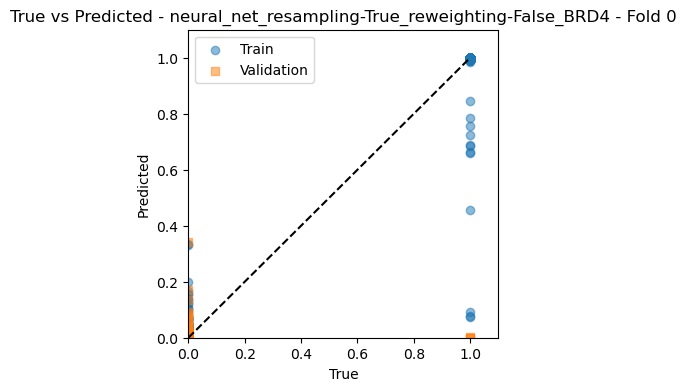

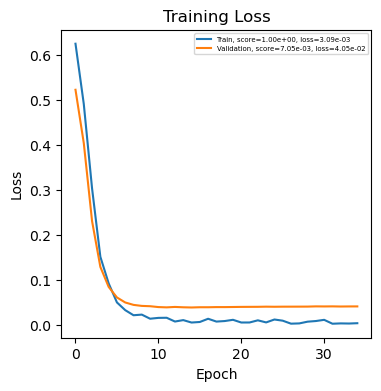

In [ ]:

from imblearn.over_sampling import SMOTE

model_name = 'neural_net' 

n_epochs = 1000
resampling = True
reweighting = False # add weight based on class imbalance

if resampling:
    # Apply SMOTE for oversampling the minority class
    smote = SMOTE(random_state=42)
    X_train_resample, y_train_resample = smote.fit_resample(X_train, y_train)

# Assuming X_train, y_train, X_test, y_test are numpy arrays
# Convert them to PyTorch tensors
if resampling:
    X_train_t = torch.tensor(X_train_resample, dtype=torch.float32)
    y_train_t = torch.tensor(y_train_resample, dtype=torch.float32)
else:
    X_train_t = torch.tensor(X_train, dtype=torch.float32)
    y_train_t = torch.tensor(y_train, dtype=torch.float32)
X_validation_t = torch.tensor(X_validation, dtype=torch.float32)
y_validation_t = torch.tensor(y_validation, dtype=torch.float32)
X_test_t = torch.tensor(X_test, dtype=torch.float32)

# Create a DataLoader for the training data
train_data = TensorDataset(X_train_t, y_train_t)
train_loader = DataLoader(train_data, batch_size=64, shuffle=True)

# Initialize the model, loss function, and optimizer
model = Net(n_features=X_train.shape[1], dropout_rate=0.3)
optimizer = optim.Adam(model.parameters(), lr=0.0001, weight_decay=0.001)

# Calculate class weights
class_counts = np.bincount(y_train_t.numpy().astype(int))
class_weights = 1. / class_counts
print('class weights: ', class_weights)
if reweighting:
    pos_weight = torch.tensor([class_weights[1]], dtype=torch.float32)
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
else:
    criterion = nn.BCELoss()

# Early stopping parameters
patience = 20  # Number of epochs to wait for improvement before stopping
best_loss = float('inf')  # Best loss value so far, initialized to infinity
epochs_no_improve = 0  # Number of epochs with no improvement, initialized to 0

train_losses = []
validation_losses = []

# Train the model
for epoch in range(n_epochs):  # 100 epochs
    for inputs, targets in train_loader:
        # Forward pass
        outputs = model(inputs)
        loss = criterion(outputs, targets.view(-1, 1))

        # Backward pass and optimization
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    
    train_losses.append(loss.item())
    if (epoch+1) % 50 == 0:
        print(f'Epoch {epoch+1}/{n_epochs}, Loss: {loss.item()}')

    # Evaluate on validation set
    model.eval()
    with torch.no_grad():
        y_validation_pred = model(X_validation_t)
        validation_loss = criterion(y_validation_pred, y_validation_t.view(-1, 1))
        validation_losses.append(validation_loss.item())

    # Check for improvement
    if validation_loss < best_loss:
        best_loss = validation_loss
        epochs_no_improve = 0
    else:
        epochs_no_improve += 1

    # Early stopping
    if epochs_no_improve == patience:
        print('Early stopping!')
        break

    model.train()

print(f'\nTrain Loss: {loss.item()}')

# Evaluate the model
model.eval()  # Set the model to evaluation mode
with torch.no_grad():
    y_train_pred = model(X_train_t)
    train_score = average_precision_score(y_train_t, y_train_pred)
    
    y_validation_pred = model(X_validation_t)
    validation_loss = criterion(y_validation_pred, y_validation_t.view(-1, 1))
    validation_score = average_precision_score(y_validation, y_validation_pred)
print(f'Validation Loss: {validation_loss.item()}')
print(f'\nTrain Score: {train_score}')
print(f'Validation Score: {validation_score}')

# save model to file
torch.save(model, 'model_'+model_name+'_resampling-{}_reweighting-{}_'.format(resampling,reweighting)+protein_name + '.pt')

# plot scatter
plot_scatter(y_train_t, y_train_pred, y_validation, y_validation_pred, prefix=model_name+'_resampling-{}_reweighting-{}_'.format(resampling,reweighting)+protein_name, fold=0)

# plot loss
plt.figure(figsize=(4, 4))
plt.plot(train_losses, label='Train, score={:.2e}, loss={:.2e}'.format(train_score,loss.item()))
plt.plot(validation_losses, label='Validation, score={:.2e}, loss={:.2e}'.format(validation_score,validation_loss.item()))
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training Loss')
plt.legend(fontsize=5)
plt.savefig(model_name+'_resampling-{}_reweighting-{}_'.format(resampling,reweighting)+protein_name +'_loss.png', dpi=500, bbox_inches='tight')
plt.show()



In [ ]:
# evaluate on test data

with torch.no_grad():
    y_test_pred = model(X_test_t)
    y_test_pred = y_test_pred.numpy().flatten()

test_ids = pd.read_csv('test_ids_' + protein_name + '.csv')
test_ids = test_ids.to_numpy().flatten()

# make a dataframe with id and binds columns
test_results = pd.DataFrame({'id': test_ids, 'binds': y_test_pred})
test_results.to_csv('test_pred_' + protein_name + '.csv', index=False)

0     295246830
3     295246833
6     295246836
9     295246839
12    295246842
Name: id, dtype: object

In [ ]:
# build Linear Regression model using 10-fold cross validation
kf = KFold(n_splits=5, shuffle=True)

model_dict = {
              'logistic_regression': LogisticRegression(class_weight='balanced', max_iter=100000, C=0.5, 
                                                        penalty='l2', solver='lbfgs'), # class_weight='balanced': weigth classes by their frequency
                                                        # C=1 gives good train score but overfitted
              'random_forest': RandomForestClassifier(min_samples_split=2,min_samples_leaf=1, n_estimators=200), #min_samples_split=5,min_samples_leaf=1,n_estimators=100), 
                                                      
              'mlp': MLPClassifier(hidden_layer_sizes=(20,20), activation='relu', 
                                   solver='adam', max_iter=10000),
              'neural_net': Net(n_features=X_train.shape[1])}
train_scores = []    
validation_scores = []
train_rmse = []
validation_rmse = []
fold_index = 0

for train_index, validation_index in kf.split(X_train):
    X_train_fold, X_validation_fold = X_train[train_index], X_train[validation_index]
    y_train_fold, y_validation_fold = y_train[train_index], y_train[validation_index]

    model = model_dict[model_name]
    model.fit(X_train_fold, y_train_fold)
    
    y_train_pred = model.predict(X_train_fold)
    score = average_precision_score(y_train_fold, y_train_pred)
    train_scores.append(score)
    rmse = np.sqrt(mean_squared_error(y_train_fold, y_train_pred))
    train_rmse.append(rmse)

    y_validation_pred = model.predict(X_validation_fold)
    score = average_precision_score(y_validation_fold, y_validation_pred)
    validation_scores.append(score)
    rmse = np.sqrt(mean_squared_error(y_validation_fold, y_validation_pred))
    validation_rmse.append(rmse)

    #plot_scatter(y_train_fold, y_train_pred, y_validation_fold, y_validation_pred, prefix=model_name+'_'+protein_name, fold=fold_index)
    
    fold_index += 1


plot_scores(train_scores, validation_scores, train_rmse, validation_rmse, prefix=model_name+'_'+protein_name)

print('Train scores: ', train_scores)
print('Validation scores: ', validation_scores)

print('Train RMSE: ', train_rmse)
print('Validation RMSE: ', validation_rmse)

print('\nTrain MEAN scores: {:.4f} +/- {:.4f}'.format(np.mean(train_scores), np.std(train_scores)))
print('Validation MEAN scores: {:.4f} +/- {:.4f}'.format(np.mean(validation_scores), np.std(validation_scores)))

print('Train MEAN RMSE: {:.4f} +/- {:.4f}'.format(np.mean(train_rmse), np.std(train_rmse)))
print('Validation MEAN RMSE: {:.4f} +/- {:.4f}'.format(np.mean(validation_rmse), np.std(validation_rmse)))

# print the model coefficients
# print('Model coefficients: ', model.coef_)
# print('Model intercept: ', model.intercept_)

print('Model parameters: ', model.get_params())

Train scores:  [0.19117647058823528]
Validation scores:  [0.005]
Train RMSE:  [0.15138251770487457]
Validation RMSE:  [0.18708286933869708]


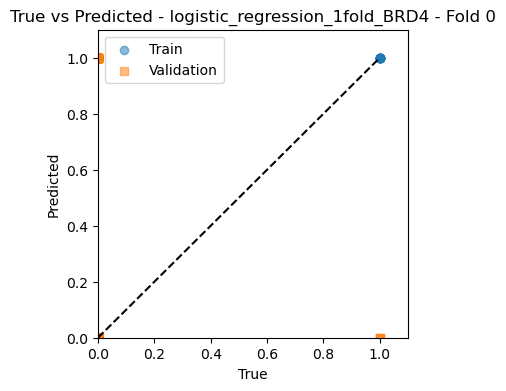

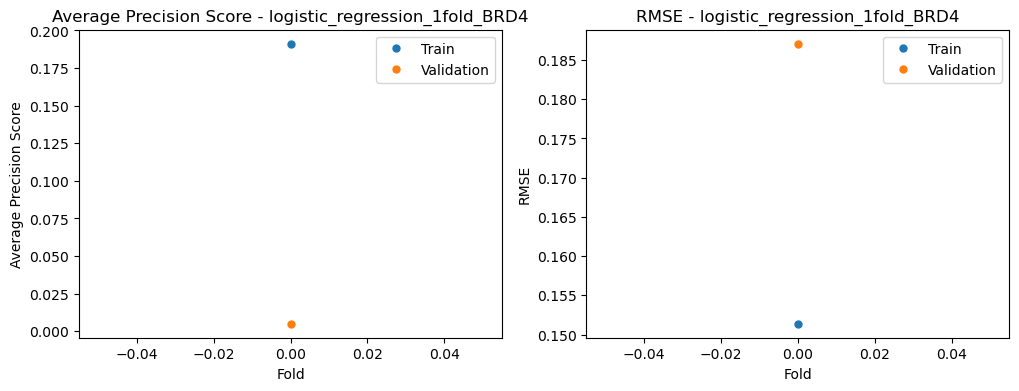

In [ ]:
# # just do 1 fold
train_scores = []    
validation_scores = []
train_rmse = []
validation_rmse = []

model = model_dict[model_name]
model.fit(X_train, y_train)
   
y_train_pred = model.predict(X_train)
score = average_precision_score(y_train, y_train_pred)
train_scores.append(score)
rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
train_rmse.append(rmse)

y_validation_pred = model.predict(X_validation)
score = average_precision_score(y_validation, y_validation_pred)
validation_scores.append(score)
rmse = np.sqrt(mean_squared_error(y_validation, y_validation_pred))
validation_rmse.append(rmse)

print('Train scores: ', train_scores)
print('Validation scores: ', validation_scores)

print('Train RMSE: ', train_rmse)
print('Validation RMSE: ', validation_rmse)

plot_scatter(y_train, y_train_pred, y_validation, y_validation_pred, prefix=model_name+'_1fold_'+protein_name, fold=0)
plot_scores(train_scores, validation_scores, train_rmse, validation_rmse, prefix=model_name+'_1fold_'+protein_name)



In [1]:

import pyarrow.parquet as pq
pkl_file = ''
parquet_file = ''
train_data = pq.read_table('../data/split1/train_folds.parquet').to_pandas()
train_data.head()


,buildingblock1_smiles,buildingblock2_smiles,buildingblock3_smiles,molecule_smiles,binds_BRD4,binds_HSA,binds_sEH,bb_test_noshare,bb_test_mixshare,random_test,full_test
0,628,941,368,C#CCOc1ccc(CNc2nc(NCC3CCCN3c3cccnn3)nc(N[C@@H]...,0,0,0,False,True,False,True
1,628,941,835,C#CCOc1ccc(CNc2nc(NCc3cccc(Br)n3)nc(N[C@@H](CC...,0,0,0,False,True,False,True
2,628,941,941,C#CCOc1ccc(CNc2nc(NCc3ccc(OCC#C)cc3)nc(N[C@@H]...,0,0,0,False,True,False,True
3,628,941,151,C#CCOc1ccc(CNc2nc(NCCNC(=O)C(=C)C)nc(N[C@@H](C...,0,0,0,False,True,False,True
4,628,941,235,C#CCOc1ccc(CNc2nc(NCC(=O)NCC=C)nc(N[C@@H](CC#C...,0,0,0,False,True,False,True


In [3]:
train_data[['bb_test_noshare', 'bb_test_mixshare', 'random_test', 'full_test']].sum()

bb_test_noshare        11226
bb_test_mixshare    13868914
random_test           295246
full_test           14122319
dtype: int64

In [6]:
train_data[['bb_test_noshare', 'bb_test_mixshare', 'random_test', 'full_test']].mean() * 100

bb_test_noshare      0.011407
bb_test_mixshare    14.092189
random_test          0.299999
full_test           14.349674
dtype: float64

In [9]:
train_data.iloc[len(train_data)-1 : len(train_data)+2]

,buildingblock1_smiles,buildingblock2_smiles,buildingblock3_smiles,molecule_smiles,binds_BRD4,binds_HSA,binds_sEH,bb_test_noshare,bb_test_mixshare,random_test,full_test
98415609,947,1048,1048,[N-]=[N+]=NCCC[C@H](Nc1nc(Nc2noc3ccc(F)cc23)nc...,0,0,0,False,False,False,False


In [4]:
# get only data with full_test=1
train_data = train_data[train_data['full_test'] == 1]

98415610

In [ ]:
train_data_short = train_data.sample(n=1000)
train_data_short.to_parquet('../data/split1/train_folds_small-1000.parquet')

In [16]:
len(train_data)
(train_data[['binds_BRD4','binds_HSA','binds_sEH']].sum()).sum()

1589906

In [21]:
train_data[['binds_BRD4','binds_HSA','binds_sEH']].sum()

binds_BRD4    456964
binds_HSA     408410
binds_sEH     724532
dtype: int64

In [23]:
train_data[['binds_BRD4', 'binds_HSA', 'binds_sEH']].values

array([[0, 0, 0],
       [0, 0, 0],
       [0, 0, 0],
       ...,
       [0, 0, 0],
       [0, 0, 0],
       [0, 0, 0]], dtype=int8)

In [12]:
# find rows in train_data where both binds_BRD4 and binds_HSA are 1
train_data[(train_data['binds_BRD4']==1) & (train_data['binds_HSA']==1)].head()

,buildingblock1_smiles,buildingblock2_smiles,buildingblock3_smiles,molecule_smiles,binds_BRD4,binds_HSA,binds_sEH,bb_test_noshare,bb_test_mixshare,random_test,full_test
2631266,959,755,1022,C=CCC[C@@H](Nc1nc(NCc2cc3c(s2)CCSC3)nc(Nc2ccc(...,1,1,0,False,True,False,True
2719294,959,477,904,C=CCC[C@@H](Nc1nc(NCC2CS(=O)(=O)c3ccccc32)nc(N...,1,1,0,False,False,False,False
2719382,959,477,518,C=CCC[C@@H](Nc1nc(Nc2ccc(=O)n(C)c2)nc(Nc2nc[nH...,1,1,0,False,False,False,False
4413557,920,744,957,CCn1nccc1CNc1nc(Nc2ccc(C(=O)NC)c(F)c2)nc(NC(CC...,1,1,0,False,True,False,True
4446402,920,755,4,COc1cc(CNc2nc(Nc3ccc(OC)c(OC)c3)nc(NC(CCC(=O)O...,1,1,0,False,True,False,True


In [11]:
test_data = pq.read_table('~/Downloads/test.parquet').to_pandas()
test_data.head()


,buildingblock1_smiles,buildingblock2_smiles,buildingblock3_smiles,molecule_smiles,is_BRD4,is_HSA,is_sEH
0,197,879,879,C#CCCC[C@H](Nc1nc(Nc2ccc(C=C)cc2)nc(Nc2ccc(C=C...,True,True,True
1,197,879,313,C#CCCC[C@H](Nc1nc(Nc2ccc(C=C)cc2)nc(Nc2ncnc3c2...,True,True,True
2,197,879,660,C#CCCC[C@H](Nc1nc(NCC2(O)CCCC2(C)C)nc(Nc2ccc(C...,True,True,True
3,197,879,239,C#CCCC[C@H](Nc1nc(Nc2ccc(C=C)cc2)nc(Nc2sc(Cl)c...,True,True,True
4,197,879,825,C#CCCC[C@H](Nc1nc(NCC2CCC(SC)CC2)nc(Nc2ccc(C=C...,True,True,True


In [15]:
test_data.buildingblock3_smiles == 879

0          True
1         False
2         False
3         False
4         False
          ...  
878017    False
878018    False
878019    False
878020    False
878021    False
Name: buildingblock3_smiles, Length: 878022, dtype: bool

In [28]:
len(train_data)

1000